<a href="https://colab.research.google.com/github/trish272000/Thesis/blob/main/notebooks/03_uncertainty_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 03 — Uncertainty-Aware Forecasts and Calibration
**Thesis:** Uncertainty-Aware Carbon Digital Twin for Sustainable Industrial Systems

Notebook 02 gave one number per day. Here every forecast becomes a **range**, and the ranges are then
**calibrated** so that a 95% range really contains about 95% of actual values.

| Method | How it produces a range |
|---|---|
| **A. XGBoost + conformal** | Takes notebook 02's XGBoost forecast and widens it by the size of its past errors |
| **B. Low–high XGBoost** | Separate models directly predict a low (2.5%), middle and high (97.5%) value for the day |
| **C. LSTM ensemble** | Five LSTMs trained separately; each predicts a value *and* its own noise level |
| **D. LSTM dropout sampling** | One LSTM run 100 times with random parts switched off |

All four are then put through **conformal calibration** on September–October (the checking period), and tested on
November–December.

**What the green power decision needs.** The plant must stay under the limit on at least 95% of days, so the key
output is a **one-sided 95% upper bound** on tomorrow's emissions: a value that tomorrow's emissions should exceed on
only about 1 day in 20. Two-sided 95% ranges are also reported, to judge forecast quality.

**Runtime:** use a GPU (Runtime → Change runtime type → T4 GPU). The LSTM ensemble trains five networks.

## Part 0 — Setup

In [1]:
import sys, os, json, time
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/thesis"
else:
    BASE = os.environ.get("THESIS_BASE", os.path.abspath("thesis"))

PROC, FIGS, MODELS = f"{BASE}/data/processed", f"{BASE}/results/figures", f"{BASE}/models"
RES = f"{BASE}/results"
for d in (FIGS, MODELS, RES):
    os.makedirs(d, exist_ok=True)
CONFIG = json.load(open(f"{BASE}/config.json"))
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/thesis


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch device:", DEVICE, "| XGBoost", xgb.__version__, "| PyTorch", torch.__version__)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Actual": "#23313B", "Naive (yesterday)": "#B0BEC5", "Naive (last week)": "#78909C",
          "XGBoost": "#0E7C7B", "LSTM": "#6C3FB0"}
MCOL = {"A. XGBoost + conformal": "#0E7C7B", "B. Low–high XGBoost": "#2E6DA4",
        "C. LSTM ensemble": "#6C3FB0", "D. LSTM dropout": "#D68910"}
QUICK_TEST = os.environ.get("NB_QUICK_TEST") == "1"   # only for automated checks; leave unset

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

PyTorch device: cuda | XGBoost 3.4.1 | PyTorch 2.11.0+cu130


In [3]:
ALPHA = 1 - CONFIG["confidence"]          # 0.05
Q_LO, Q_HI, Q_UP = ALPHA / 2, 1 - ALPHA / 2, 1 - ALPHA   # 2.5%, 97.5% (two-sided) and 95% (one-sided)
print(f"Two-sided range: {Q_LO:.3f}-{Q_HI:.3f} | one-sided upper bound: {Q_UP:.2f}")

Two-sided range: 0.025-0.975 | one-sided upper bound: 0.95


## Part 1 — Data (same preparation as notebook 02)
Hourly energy, Korean holidays, and inputs known the evening before.

In [4]:
steel = pd.read_parquet(f"{PROC}/steel_prepared.parquet")
daily_info = pd.read_parquet(f"{PROC}/steel_daily.parquet")[["day", "cap_t"]]

steel["ts_hour"] = steel["ts"].dt.floor("h")
hourly = (steel.groupby("ts_hour")
          .agg(kwh=("kwh", "sum"), co2_t=("co2_india_t", "sum"),
               ef=("grid_ef_t_per_mwh", "mean"), split=("split", "first"))
          .reset_index().rename(columns={"ts_hour": "ts"}))
hourly = hourly.set_index("ts").asfreq("h")                     # makes any missing hour visible
print("Missing hours:", int(hourly["kwh"].isna().sum()))
hourly["kwh"] = hourly["kwh"].interpolate(limit=3)
hourly["ef"] = hourly["ef"].ffill()
hourly["split"] = hourly["split"].ffill()
hourly = hourly.reset_index()
print(hourly.shape, hourly["ts"].min(), "to", hourly["ts"].max())
hourly.head()

Missing hours: 0
(8760, 5) 2018-01-01 00:00:00 to 2018-12-31 23:00:00


,ts,kwh,co2_t,ef,split
0,2018-01-01 00:00:00,13.72,0.010863,0.791782,train
1,2018-01-01 01:00:00,14.30,0.011348,0.793558,train
2,2018-01-01 02:00:00,13.76,0.010948,0.795624,train
3,2018-01-01 03:00:00,14.47,0.011538,0.797391,train
4,2018-01-01 04:00:00,13.89,0.011085,0.798091,train


In [5]:
KR_HOLIDAYS_2018 = pd.to_datetime([
    "2018-01-01",                                   # New Year
    "2018-02-15", "2018-02-16", "2018-02-17",       # Lunar New Year (Seollal)
    "2018-03-01",                                   # Independence Movement Day
    "2018-05-05", "2018-05-07",                     # Children's Day (+ substitute)
    "2018-05-22",                                   # Buddha's Birthday
    "2018-06-06",                                   # Memorial Day
    "2018-06-13",                                   # Local elections
    "2018-08-15",                                   # Liberation Day
    "2018-09-23", "2018-09-24", "2018-09-25", "2018-09-26",   # Chuseok (+ substitute)
    "2018-10-03", "2018-10-09",                     # National Foundation Day, Hangul Day
    "2018-12-25",                                   # Christmas
])

hourly["day"] = hourly["ts"].dt.normalize()
hourly["hour"] = hourly["ts"].dt.hour
hourly["dow"] = hourly["ts"].dt.dayofweek
hourly["month"] = hourly["ts"].dt.month
hourly["holiday"] = hourly["day"].isin(KR_HOLIDAYS_2018).astype(int)
hourly["off_day"] = ((hourly["dow"] >= 5) | (hourly["holiday"] == 1)).astype(int)

# Check: do holidays really look like weekends?
d = hourly.groupby("day").agg(kwh=("kwh", "sum"), dow=("dow", "first"), holiday=("holiday", "first"))
print("Mean daily kWh  | weekday:", round(d[(d.dow < 5) & (d.holiday == 0)].kwh.mean()),
      "| weekend:", round(d[d.dow >= 5].kwh.mean()),
      "| weekday holiday:", round(d[(d.dow < 5) & (d.holiday == 1)].kwh.mean()))

Mean daily kWh  | weekday: 3333 | weekend: 1126 | weekday holiday: 1510


In [6]:
H = hourly.copy()
H["lag_24"] = H["kwh"].shift(24)
H["lag_168"] = H["kwh"].shift(168)
day_tot = H.groupby("day")["kwh"].sum()
H["yday_total"] = H["day"].map(day_tot.shift(1))
H["lweek_total"] = H["day"].map(day_tot.shift(7))
H["mean7_same_hour"] = H.groupby("hour")["kwh"].transform(lambda s: s.shift(1).rolling(7).mean())

# Most recent earlier day of the same type (work day or off day), same hour
days = H.groupby("day")["off_day"].first()
prev_same = {}
last_seen = {}
for dday, off in days.items():
    prev_same[dday] = last_seen.get(off)
    last_seen[off] = dday
kwh_by_dh = H.set_index(["day", "hour"])["kwh"]
H["prev_same_type_day"] = H["day"].map(prev_same)
H["lag_same_type"] = [kwh_by_dh.get((p, h), np.nan) if pd.notna(p) else np.nan
                      for p, h in zip(H["prev_same_type_day"], H["hour"])]

FEATURES = ["hour", "dow", "month", "off_day", "holiday", "lag_24", "lag_168", "yday_total",
            "lweek_total", "mean7_same_hour", "lag_same_type"]

# Early-stopping period: last 4 weeks of training (August); the rest is used for fitting
H["role"] = H["split"]
H.loc[(H["split"] == "train") & (H["month"] == 8), "role"] = "valid"
H = H.dropna(subset=FEATURES + ["kwh"]).reset_index(drop=True)
print(H["role"].value_counts().reindex(["train", "valid", "calib", "test"]))

role
train    4920
valid     744
calib    1464
test     1464
Name: count, dtype: int64


In [7]:
# Daily table: actual emissions, notebook 02 point forecasts, and the emission limit
base_daily = pd.read_parquet(f"{PROC}/baseline_forecasts_daily.parquet")
DAYS = (H.groupby("day").agg(role=("role", "first"), co2=("co2_t", "sum"), kwh=("kwh", "sum"),
                             off_day=("off_day", "first"), dow=("dow", "first"),
                             holiday=("holiday", "first"), month=("month", "first"))
        .reset_index())
DAYS = DAYS[H.groupby("day").size().values == 24].reset_index(drop=True)     # complete days only
DAYS = DAYS.merge(base_daily[["day", "co2_XGBoost", "co2_LSTM", "cap_t"]], on="day", how="left")
print(DAYS["role"].value_counts().reindex(["train", "valid", "calib", "test"]))

role
train    205
valid     31
calib     61
test      61
Name: count, dtype: int64


## Part 2 — Conformal calibration (the tool used by every method)
**Idea.** Look at how wrong the raw ranges were on the checking days, then stretch (or shrink) them by just enough
that the right share of checking days falls inside.

* **Two-sided range [low, high]:** score = how far the actual value fell *outside* the range (negative if inside).
  The ranges are widened on both sides by the score at the 95% level.
* **One-sided upper bound:** score = actual − upper bound. The bound is raised by the score at the 95% level.

With *n* checking days, the level used is ⌈(n+1)(1−α)⌉ / n, which gives the coverage guarantee
(Angelopoulos & Bates, 2023; Romano et al., 2019).

In [8]:
def conformal_level(n, alpha):
    return min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)

def calibrate_two_sided(lo_cal, hi_cal, y_cal, alpha=ALPHA):
    scores = np.maximum(lo_cal - y_cal, y_cal - hi_cal)
    return np.quantile(scores, conformal_level(len(scores), alpha), method="higher")

def calibrate_upper(up_cal, y_cal, alpha=ALPHA):
    scores = y_cal - up_cal
    return np.quantile(scores, conformal_level(len(scores), alpha), method="higher")

def interval_score(lo, hi, y, alpha=ALPHA):
    # Winkler score: width plus a penalty for every miss (lower is better)
    return (hi - lo) + (2 / alpha) * (lo - y) * (y < lo) + (2 / alpha) * (y - hi) * (y > hi)

def crps_from_samples(samples, y):
    # Continuous ranked probability score for each day (lower is better)
    s = np.sort(samples, axis=1)
    m = s.shape[1]
    term1 = np.mean(np.abs(s - y[:, None]), axis=1)
    i = np.arange(1, m + 1)
    term2 = np.sum((2 * i - m - 1) * s, axis=1) / (m * m)
    return term1 - term2

RESULTS = {}     # method -> DataFrame with one row per calib/test day

## Part 3 — Method A: XGBoost + conformal
The simplest approach: no new model. Notebook 02's XGBoost daily forecast becomes the centre, and the range is set by
the size of its errors on the checking days.

In [9]:
def add_method(name, df_days, point, lo, hi, up, samples=None):
    out = df_days[["day", "role", "co2", "cap_t", "off_day"]].copy()
    out["point"], out["lo_raw"], out["hi_raw"], out["up_raw"] = point, lo, hi, up
    cal = out["role"] == "calib"
    q2 = calibrate_two_sided(out.loc[cal, "lo_raw"].values, out.loc[cal, "hi_raw"].values, out.loc[cal, "co2"].values)
    q1 = calibrate_upper(out.loc[cal, "up_raw"].values, out.loc[cal, "co2"].values)
    out["lo"] = np.clip(out["lo_raw"] - q2, 0, None)
    out["hi"] = out["hi_raw"] + q2
    out["up"] = out["up_raw"] + q1
    out.attrs = {"q_two_sided": float(q2), "q_upper": float(q1)}
    RESULTS[name] = (out, samples)
    print(f"{name}: two-sided correction {q2:+.3f} t | upper-bound correction {q1:+.3f} t")
    return out

A = DAYS[DAYS.role.isin(["calib", "test"])].reset_index(drop=True)
pA = A["co2_XGBoost"].values
add_method("A. XGBoost + conformal", A, pA, pA, pA, pA);

A. XGBoost + conformal: two-sided correction +1.926 t | upper-bound correction +0.840 t


## Part 4 — Method B: Low–high XGBoost (quantile regression)
Three XGBoost models predict the day's emissions directly: a **low** value (2.5%), a **middle** value (50%) and a
**high** value (97.5%), plus a **95% one-sided** upper value. They learn from daily inputs known the evening before.

In [10]:
day_co2 = H.groupby("day")["co2_t"].sum()
day_kwh = H.groupby("day")["kwh"].sum()
D2 = DAYS.copy()
D2["yday_co2"] = D2["day"].map(day_co2.shift(1))
D2["lweek_co2"] = D2["day"].map(day_co2.shift(7))
D2["mean7_co2"] = D2["day"].map(day_co2.shift(1).rolling(7).mean())
D2["std7_co2"] = D2["day"].map(day_co2.shift(1).rolling(7).std())
type_of = H.groupby("day")["off_day"].first()
last_same = {}
prev_val = {}
for dday in type_of.index:
    prev_val[dday] = last_same.get(type_of[dday], np.nan)
    last_same[type_of[dday]] = day_co2.get(dday, np.nan)
D2["last_same_type_co2"] = D2["day"].map(prev_val)
DFEAT = ["dow", "off_day", "holiday", "month", "yday_co2", "lweek_co2", "mean7_co2", "std7_co2", "last_same_type_co2"]
D2 = D2.dropna(subset=DFEAT).reset_index(drop=True)

def fit_quantile(q):
    m = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=q, n_estimators=1500,
                         learning_rate=0.03, max_depth=3, min_child_weight=3, subsample=0.8,
                         colsample_bytree=0.8, early_stopping_rounds=100, random_state=SEED)
    tr, va = D2.role == "train", D2.role == "valid"
    m.fit(D2.loc[tr, DFEAT], D2.loc[tr, "co2"], eval_set=[(D2.loc[va, DFEAT], D2.loc[va, "co2"])], verbose=False)
    m.save_model(f"{MODELS}/xgb_quantile_{int(q*1000)}.json")
    return m.predict(D2[DFEAT])

qpred = {q: fit_quantile(q) for q in (Q_LO, 0.5, Q_UP, Q_HI)}
# Quantile models are trained separately, so their lines can cross; sort them per day
stack = np.sort(np.column_stack([qpred[Q_LO], qpred[0.5], qpred[Q_UP], qpred[Q_HI]]), axis=1)
D2["q_lo"], D2["q_mid"], D2["q_up"], D2["q_hi"] = stack.T
B = D2[D2.role.isin(["calib", "test"])].reset_index(drop=True)
add_method("B. Low–high XGBoost", B, B["q_mid"].values, B["q_lo"].values, B["q_hi"].values, B["q_up"].values);

B. Low–high XGBoost: two-sided correction +0.022 t | upper-bound correction +0.028 t


## Part 5 — LSTM windows (same as notebook 02)

In [11]:
LOOKBACK, HORIZON = 168, 24
series = hourly.set_index("ts")["kwh"]
SCALE = float(series[hourly.set_index("ts")["split"] == "train"].max())
y_all = (series / SCALE).values.astype(np.float32)
ts_all = series.index
cal = np.stack([np.sin(2*np.pi*ts_all.hour/24), np.cos(2*np.pi*ts_all.hour/24),
                np.sin(2*np.pi*ts_all.dayofweek/7), np.cos(2*np.pi*ts_all.dayofweek/7),
                (ts_all.dayofweek >= 5) | ts_all.normalize().isin(KR_HOLIDAYS_2018)], axis=1).astype(np.float32)
role_all = pd.Series(hourly["split"].values, index=ts_all)
role_all[(role_all == "train") & (ts_all.month == 8)] = "valid"

def make_windows(roles, midnight_only):
    X, C, Y, T = [], [], [], []
    for t in range(LOOKBACK, len(y_all) - HORIZON + 1):
        if midnight_only and ts_all[t].hour != 0:
            continue
        if role_all.iloc[t] not in roles or role_all.iloc[t + HORIZON - 1] not in roles:
            continue
        past = y_all[t - LOOKBACK:t]
        if np.isnan(past).any() or np.isnan(y_all[t:t + HORIZON]).any():
            continue
        X.append(np.stack([past, cal[t - LOOKBACK:t, 4]], axis=1))   # usage + off-day flag
        C.append(cal[t:t + HORIZON])                                   # tomorrow's calendar
        Y.append(y_all[t:t + HORIZON]); T.append(ts_all[t])
    return (torch.tensor(np.array(X)), torch.tensor(np.array(C)),
            torch.tensor(np.array(Y)), pd.DatetimeIndex(T))

Xtr_l, Ctr_l, Ytr_l, _ = make_windows({"train"}, midnight_only=False)
Xva_l, Cva_l, Yva_l, _ = make_windows({"valid"}, midnight_only=True)
print("LSTM training examples:", len(Xtr_l), "| early-stopping days:", len(Xva_l))

LSTM training examples: 4897 | early-stopping days: 31


In [12]:
class ProbLSTM(nn.Module):
    # Like notebook 02's LSTM, but each hour gets two outputs: a value and its noise level (log-variance)
    def __init__(self, n_in=2, n_cal=5, hidden=64, dropout=0.2):
        super().__init__()
        self.encoder = nn.LSTM(n_in, hidden, num_layers=2, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden + n_cal, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 2))

    def forward(self, x, c):
        _, (h, _) = self.encoder(x)
        h = h[-1].unsqueeze(1).expand(-1, c.shape[1], -1)
        out = self.head(torch.cat([h, c], dim=-1))
        mean, logvar = out[..., 0], out[..., 1].clamp(-12, 4)
        return mean, logvar

def train_prob_lstm(seed, epochs=200, patience=20, lr=1e-3, batch=128):
    torch.manual_seed(seed); np.random.seed(seed)
    model = ProbLSTM().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    nll = nn.GaussianNLLLoss()
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_l))
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            mu, lv = model(Xtr_l[idx].to(DEVICE), Ctr_l[idx].to(DEVICE))
            loss = nll(mu, Ytr_l[idx].to(DEVICE), lv.exp())
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            mu, lv = model(Xva_l.to(DEVICE), Cva_l.to(DEVICE))
            v = nll(mu, Yva_l.to(DEVICE), lv.exp()).item()
        hist.append(v)
        if v < best - 1e-6:
            best, best_state, wait = v, {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, hist

# Day-ahead windows (midnight starts) for the checking and testing days
Xev, Cev, Yev, Tev = make_windows({"calib", "test"}, midnight_only=True)
EF_EV = np.stack([hourly.set_index("ts")["ef"].reindex(pd.date_range(t, periods=HORIZON, freq="h")).values
                  for t in Tev])                                       # tCO2/MWh for each forecast hour
print("Evaluation days:", len(Tev))

def to_daily_co2(hourly_kwh_samples):
    # hourly_kwh_samples: (days, samples, 24) in kWh  ->  (days, samples) daily tCO2
    return np.einsum("dsh,dh->ds", np.clip(hourly_kwh_samples, 0, None) / 1000, EF_EV)

Evaluation days: 122


## Part 6 — Method C: LSTM ensemble (five networks)
Each network predicts, for every hour, a **value** and a **noise level**. Training five networks from different random
starts gives five slightly different opinions.

* **Measurement noise (aleatoric):** the average of the five noise levels — randomness in the plant itself.
* **Model doubt (epistemic):** how much the five values disagree — shrinks with more data.

Daily emission samples are drawn from all five networks, and their spread gives the raw range.

In [13]:
N_MEMBERS = 2 if QUICK_TEST else 5
EPOCHS = 2 if QUICK_TEST else 200
members = []
t0 = time.time()
for k in range(N_MEMBERS):
    m, hist = train_prob_lstm(seed=SEED + k, epochs=EPOCHS)
    members.append(m)
    torch.save(m.state_dict(), f"{MODELS}/lstm_ensemble_{k}.pt")
    print(f"  network {k+1}/{N_MEMBERS}: {len(hist)} epochs, best validation loss {min(hist):.3f}")
print(f"Ensemble trained in {time.time()-t0:.0f}s")

S_PER = 40 if QUICK_TEST else 200
rng = np.random.default_rng(SEED)
mus, vars_ = [], []
with torch.no_grad():
    for m in members:
        m.eval()
        mu, lv = m(Xev.to(DEVICE), Cev.to(DEVICE))
        mus.append(mu.cpu().numpy() * SCALE); vars_.append(lv.exp().cpu().numpy() * SCALE ** 2)
mus, vars_ = np.stack(mus), np.stack(vars_)                  # (members, days, 24)
aleatoric_h = vars_.mean(0)
epistemic_h = mus.var(0)
samples_C = np.concatenate([rng.normal(mus[k][:, None, :], np.sqrt(vars_[k])[:, None, :],
                                       size=(len(Tev), S_PER, HORIZON)) for k in range(N_MEMBERS)], axis=1)
daily_C = to_daily_co2(samples_C)                            # (days, samples)

  network 1/5: 69 epochs, best validation loss -2.280
  network 2/5: 58 epochs, best validation loss -2.238
  network 3/5: 52 epochs, best validation loss -2.300
  network 4/5: 59 epochs, best validation loss -2.392
  network 5/5: 80 epochs, best validation loss -2.280
Ensemble trained in 79s


C. LSTM ensemble: two-sided correction +0.581 t | upper-bound correction +0.650 t


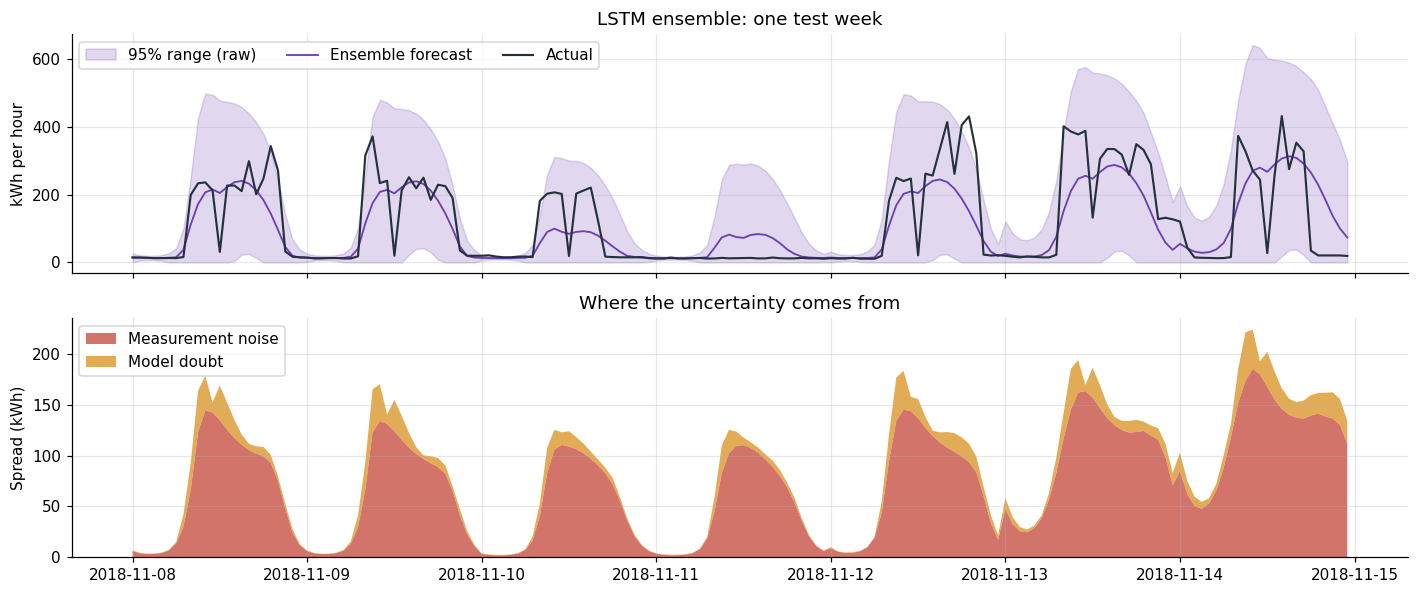

Share of uncertainty from measurement noise: 97% | from model doubt: 3%


In [14]:
def from_samples(name, daily_samples):
    df = pd.DataFrame({"day": Tev.normalize()}).merge(DAYS, on="day", how="left")
    q = np.quantile(daily_samples, [Q_LO, 0.5, Q_UP, Q_HI], axis=1)
    return add_method(name, df, q[1], q[0], q[3], q[2], samples=daily_samples)

C = from_samples("C. LSTM ensemble", daily_C)

# Uncertainty split for one test week (hourly)
roles_ev = pd.Series([role_all[t] for t in Tev])
first_test = int(np.argmax(roles_ev.values == "test")) + 7
sl = slice(first_test, first_test + 7)
hrs = pd.DatetimeIndex([t + pd.Timedelta(hours=h) for t in Tev[sl] for h in range(HORIZON)])
fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
mean_ens = mus.mean(0)[sl].ravel()
tot_sd = np.sqrt(aleatoric_h[sl] + epistemic_h[sl]).ravel()
ax[0].fill_between(hrs, np.clip(mean_ens - 1.96 * tot_sd, 0, None), mean_ens + 1.96 * tot_sd,
                   color="#6C3FB0", alpha=0.2, label="95% range (raw)")
ax[0].plot(hrs, mean_ens, color="#6C3FB0", lw=1.2, label="Ensemble forecast")
ax[0].plot(hrs, Yev[sl].numpy().ravel() * SCALE, color="#23313B", lw=1.4, label="Actual")
ax[0].set(ylabel="kWh per hour", title="LSTM ensemble: one test week"); ax[0].legend(ncol=3)
ax[1].stackplot(hrs, np.sqrt(aleatoric_h[sl]).ravel(), np.sqrt(epistemic_h[sl]).ravel(),
                colors=["#C0392B", "#D68910"], alpha=0.7, labels=["Measurement noise", "Model doubt"])
ax[1].set(ylabel="Spread (kWh)", title="Where the uncertainty comes from"); ax[1].legend(loc="upper left")
savefig("03_ensemble_week")

share_noise = aleatoric_h.sum() / (aleatoric_h.sum() + epistemic_h.sum())
print(f"Share of uncertainty from measurement noise: {share_noise:.0%} | from model doubt: {1-share_noise:.0%}")

## Part 7 — Method D: LSTM dropout sampling
One network (the first ensemble member) is run 100 times with dropout **left on**, so each run switches off a
different random part of the network. Each run also draws noise from its predicted noise level.

In [15]:
T_PASSES = 10 if QUICK_TEST else 100
net = members[0]
net.train()                       # keeps dropout active
draws = []
with torch.no_grad():
    for _ in range(T_PASSES):
        mu, lv = net(Xev.to(DEVICE), Cev.to(DEVICE))
        mu, sd = mu.cpu().numpy() * SCALE, lv.exp().sqrt().cpu().numpy() * SCALE
        draws.append(rng.normal(mu[:, None, :], sd[:, None, :], size=(len(Tev), 2, HORIZON)))
net.eval()
samples_D = np.concatenate(draws, axis=1)
daily_D = to_daily_co2(samples_D)
Dm = from_samples("D. LSTM dropout", daily_D)

D. LSTM dropout: two-sided correction +0.606 t | upper-bound correction +0.690 t


## Part 8 — Do the ranges hold? (test period, November–December)

| Measure | Meaning | Target |
|---|---|---|
| **Coverage** | share of days whose actual emissions fall inside the two-sided range | ≈ 95% |
| **Width** | average width of the range (tCO₂) | as narrow as possible *while* covering |
| **Interval score** | width plus a penalty for each miss | lower is better |
| **Upper-bound exceedance** | share of days above the one-sided 95% bound | ≈ 5% |
| **Weighted error** | total |forecast − actual| ÷ total actual emissions | lower is better |
| **CRPS** | quality of the whole forecast distribution (sampling methods only) | lower is better |

In [16]:
rows = []
for name, (df, samples) in RESULTS.items():
    for stage, (lo, hi, up) in {"raw": ("lo_raw", "hi_raw", "up_raw"), "calibrated": ("lo", "hi", "up")}.items():
        for r in ["calib", "test"]:
            k = (df["role"] == r).values
            d = df[k]
            y = d["co2"].values
            row = {"method": name, "stage": stage, "period": r,
                   "coverage (%)": 100 * np.mean((y >= d[lo]) & (y <= d[hi])),
                   "width (t)": np.mean(d[hi] - d[lo]),
                   "interval score": np.mean(interval_score(d[lo].values, d[hi].values, y)),
                   "above upper bound (%)": 100 * np.mean(y > d[up]),
                   "weighted error (%)": 100 * np.abs(d["point"] - y).sum() / y.sum()}
            if samples is not None and stage == "raw":
                row["CRPS"] = np.mean(crps_from_samples(samples[k], y))
            rows.append(row)
EVAL = pd.DataFrame(rows).set_index(["period", "stage", "method"]).sort_index()
EVAL.to_csv(f"{RES}/03_uncertainty_metrics.csv")
print(EVAL.loc["test"].round(3).to_string())

                                   coverage (%)  width (t)  interval score  above upper bound (%)  weighted error (%)   CRPS
stage      method                                                                                                           
calibrated A. XGBoost + conformal       100.000      3.471           3.471                  4.918              26.795    NaN
           B. Low–high XGBoost           98.361      2.485           2.572                  4.918              27.815    NaN
           C. LSTM ensemble              96.721      2.170           2.461                  1.639              27.061    NaN
           D. LSTM dropout               96.721      2.141           2.695                  0.000              29.067    NaN
raw        A. XGBoost + conformal         0.000      0.000          16.580                 44.262              26.795    NaN
           B. Low–high XGBoost           98.361      2.442           2.543                  4.918              27.815    NaN


**How to read this.** *Raw* ranges come straight from each model; *calibrated* ranges have been adjusted on the
checking period. Good calibrated ranges show coverage near 95% and upper-bound exceedance near 5% on the **test**
period, which the calibration never saw. Among methods that achieve this, the narrowest range (lowest interval score)
is the most useful.

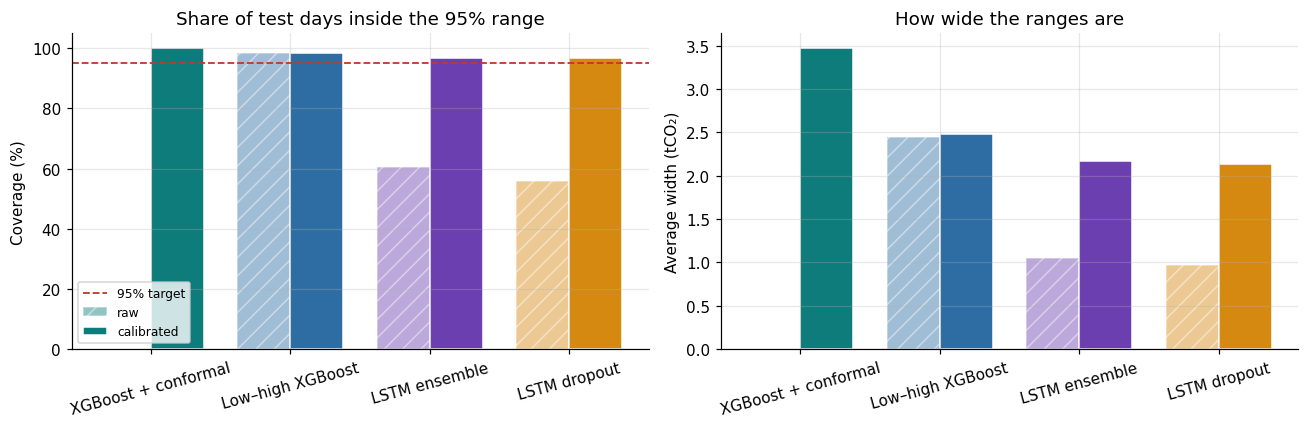

In [17]:
# Coverage and width, raw vs calibrated (test period)
t = EVAL.loc["test"].reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
names = list(RESULTS)
x = np.arange(len(names))
for j, (stage, hatch) in enumerate([("raw", "//"), ("calibrated", "")]):
    s = t[t.stage == stage].set_index("method").reindex(names)
    ax[0].bar(x + (j - 0.5) * 0.38, s["coverage (%)"], 0.38, color=[MCOL[n] for n in names],
              alpha=0.45 if stage == "raw" else 1, hatch=hatch, edgecolor="white", label=stage)
    ax[1].bar(x + (j - 0.5) * 0.38, s["width (t)"], 0.38, color=[MCOL[n] for n in names],
              alpha=0.45 if stage == "raw" else 1, hatch=hatch, edgecolor="white", label=stage)
ax[0].axhline(95, color="#C0392B", ls="--", lw=1.2, label="95% target")
ax[0].set(ylabel="Coverage (%)", title="Share of test days inside the 95% range", ylim=(0, 105))
ax[1].set(ylabel="Average width (tCO₂)", title="How wide the ranges are")
for a in ax:
    a.set_xticks(x); a.set_xticklabels([n.split(". ")[1] for n in names], rotation=15)
ax[0].legend(fontsize=8)
savefig("03_coverage_width")

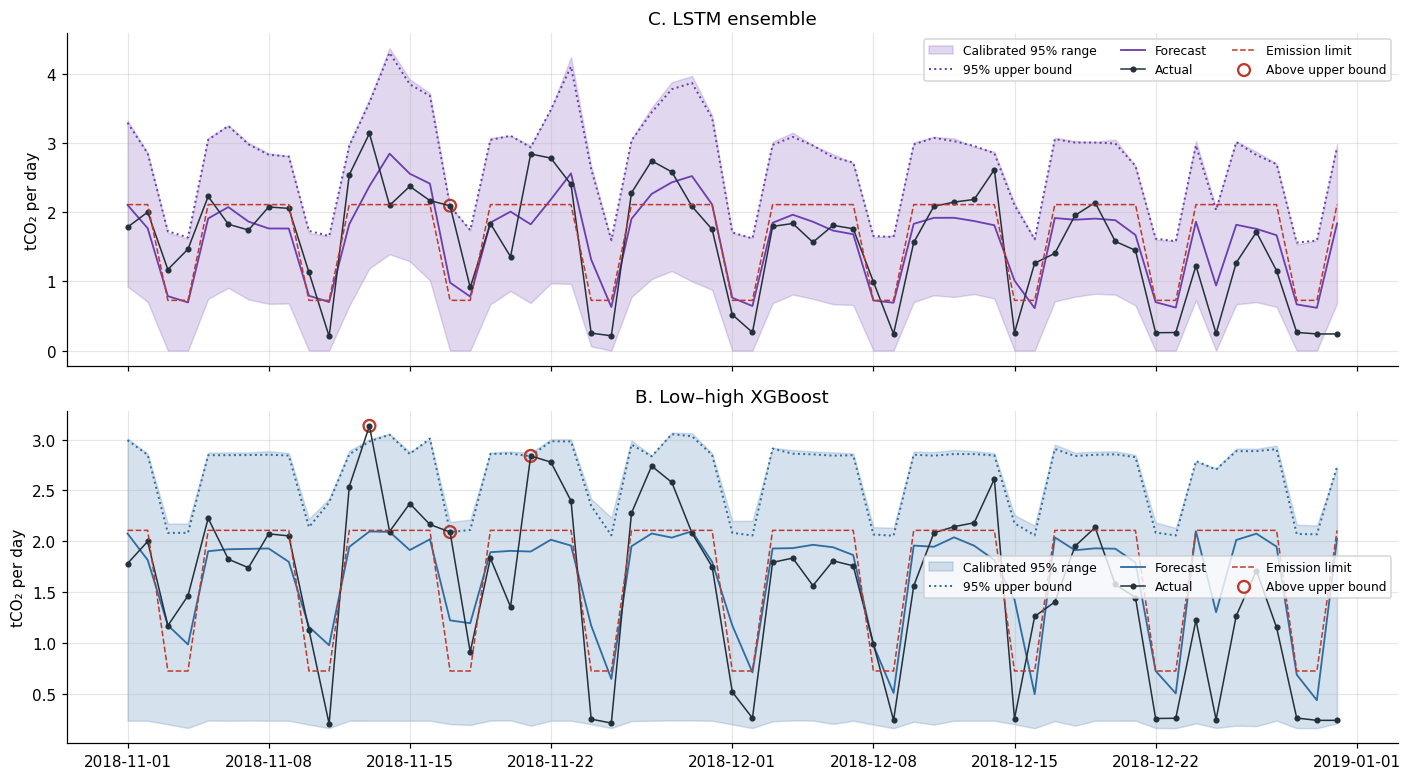

In [18]:
# Daily emissions with calibrated ranges, test period, best two methods by interval score
best = (t[t.stage == "calibrated"].sort_values("interval score")["method"].head(2).tolist())
fig, axes = plt.subplots(len(best), 1, figsize=(13, 3.6 * len(best)), sharex=True)
axes = np.atleast_1d(axes)
for a, name in zip(axes, best):
    d = RESULTS[name][0]
    d = d[d.role == "test"]
    a.fill_between(d["day"], d["lo"], d["hi"], color=MCOL[name], alpha=0.2, label="Calibrated 95% range")
    a.plot(d["day"], d["up"], color=MCOL[name], ls=":", lw=1.3, label="95% upper bound")
    a.plot(d["day"], d["point"], color=MCOL[name], lw=1.2, label="Forecast")
    a.plot(d["day"], d["co2"], "o-", color="#23313B", ms=3, lw=1, label="Actual")
    a.plot(d["day"], d["cap_t"], color="#C0392B", ls="--", lw=1, label="Emission limit")
    miss = d["co2"] > d["up"]
    a.scatter(d.loc[miss, "day"], d.loc[miss, "co2"], s=60, facecolors="none", edgecolors="#C0392B", lw=1.5,
              label="Above upper bound")
    a.set(ylabel="tCO₂ per day", title=name); a.legend(ncol=3, fontsize=8)
savefig("03_daily_ranges")

In [19]:
# Do ranges adapt? Width on work days vs off days (calibrated, test period)
wd = []
for name, (df, _) in RESULTS.items():
    d = df[df.role == "test"]
    for off, g in d.groupby("off_day"):
        wd.append({"method": name, "day type": "off day" if off else "work day",
                   "mean width (t)": (g["hi"] - g["lo"]).mean(), "mean emissions (t)": g["co2"].mean()})
print(pd.DataFrame(wd).pivot(index="method", columns="day type", values="mean width (t)").round(3).to_string())

day type                off day  work day
method                                   
A. XGBoost + conformal    2.774     3.787
B. Low–high XGBoost       2.057     2.679
C. LSTM ensemble          1.758     2.357
D. LSTM dropout           1.756     2.315


A useful forecast gives **narrower ranges on off days** (little happens) and **wider ranges on work days** (more can
vary). Method A gives the same width every day, because conformal widening of a single forecast is a fixed amount;
methods B–D can adapt.

## Part 9 — Adaptive calibration over the test period
Plants change over time (seasons, maintenance, order books). Adaptive conformal inference (Gibbs & Candès, 2021)
updates the upper bound **day by day**: after a day above the bound, the next bound is raised; after a day inside it,
the bound relaxes slightly. Each new day's error is also added to the history.

In [20]:
GAMMA = 0.02           # step size: how strongly each miss moves the level

def adaptive_upper(df):
    d = df.sort_values("day").reset_index(drop=True)
    cal = d[d.role == "calib"]
    scores = list((cal["co2"] - cal["up_raw"]).values)
    a_t, out = ALPHA, []
    for _, row in d[d.role == "test"].iterrows():
        level = np.clip(1 - a_t, 0, 1)
        q = np.quantile(scores, min(1.0, np.ceil((len(scores) + 1) * level) / len(scores)), method="higher") \
            if a_t > 0 else np.max(scores) * 1.5
        bound = row["up_raw"] + q
        miss = float(row["co2"] > bound)
        out.append({"day": row["day"], "up_adaptive": bound, "miss": miss, "alpha_t": a_t})
        a_t = a_t + GAMMA * (ALPHA - miss)
        scores.append(row["co2"] - row["up_raw"])
    return pd.DataFrame(out)

rows = []
for name, (df, _) in RESULTS.items():
    ad = adaptive_upper(df)
    df_t = df[df.role == "test"].merge(ad[["day", "up_adaptive"]], on="day")
    RESULTS[name][0].loc[RESULTS[name][0].role == "test", "up_adaptive"] = df_t["up_adaptive"].values
    rows.append({"method": name,
                 "fixed: above bound (%)": 100 * np.mean(df_t["co2"] > df_t["up"]),
                 "adaptive: above bound (%)": 100 * ad["miss"].mean(),
                 "fixed: mean bound (t)": df_t["up"].mean(),
                 "adaptive: mean bound (t)": ad["up_adaptive"].mean()})
ADAPT = pd.DataFrame(rows).set_index("method")
ADAPT.to_csv(f"{RES}/03_adaptive_calibration.csv")
print(ADAPT.round(3).to_string())

                        fixed: above bound (%)  adaptive: above bound (%)  fixed: mean bound (t)  adaptive: mean bound (t)
method                                                                                                                    
A. XGBoost + conformal                   4.918                      4.918                  2.468                     2.616
B. Low–high XGBoost                      4.918                      3.279                  2.655                     2.645
C. LSTM ensemble                         1.639                      1.639                  2.714                     2.607
D. LSTM dropout                          0.000                      1.639                  2.826                     2.623


## Part 10 — Preview: green power bought with the 95% upper bound
Same rule as notebook 02's preview, but the plant now plans on the **calibrated upper bound** instead of the
single forecast: *f* = max(0, 1 − limit / upper bound). The full decision study (with emission-factor uncertainty,
scheduling and penalties) is notebook 04.

In [21]:
premium = CONFIG["green_premium_rs_per_kwh"]
energy = DAYS.set_index("day")["kwh"]
rows = []
def evaluate(label, d, plan_value):
    f = np.clip(1 - d["cap_t"] / np.clip(plan_value, 1e-6, None), 0, 1)
    realised = (1 - f) * d["co2"]
    over = realised > d["cap_t"] * (1 + 1e-4)
    rows.append({"method": label, "days over limit (%)": 100 * over.mean(),
                 "excess CO2 (t)": (realised - d["cap_t"])[over].sum(),
                 "green power cost (Rs)": (f * d["day"].map(energy) * premium).sum()})

ref = RESULTS["A. XGBoost + conformal"][0]
ref = ref[ref.role == "test"]
evaluate("Single forecast (XGBoost, notebook 02)", ref, ref["point"])
for name, (df, _) in RESULTS.items():
    d = df[df.role == "test"]
    evaluate(f"{name}: 95% upper bound", d, d["up"])
    evaluate(f"{name}: adaptive upper bound", d, d["up_adaptive"])
evaluate("Perfect knowledge", ref, ref["co2"])
PREVIEW = pd.DataFrame(rows).set_index("method")
PREVIEW.to_csv(f"{RES}/03_green_power_preview.csv")
print(PREVIEW.round(1).to_string())

                                              days over limit (%)  excess CO2 (t)  green power cost (Rs)
method                                                                                                  
Single forecast (XGBoost, notebook 02)                       34.4             6.9                 2031.6
A. XGBoost + conformal: 95% upper bound                       4.9             0.4                14618.1
A. XGBoost + conformal: adaptive upper bound                  4.9             0.2                16385.3
B. Low–high XGBoost: 95% upper bound                          3.3             0.1                15849.3
B. Low–high XGBoost: adaptive upper bound                     3.3             0.2                15783.7
C. LSTM ensemble: 95% upper bound                             1.6             0.0                17881.4
C. LSTM ensemble: adaptive upper bound                        1.6             0.1                16777.5
D. LSTM dropout: 95% upper bound                       

**What to look for.** Planning on the calibrated upper bound should bring the days over the limit down to about 5%,
at a higher green power cost than the single forecast. The method with the **lowest cost at about 5% of days over**
is the best twin. Notebook 04 adds emission-factor uncertainty and a penalty for breaches, and compares this
risk-aware plan with a fixed worst-case plan.

## Part 11 — Save for notebook 04

In [22]:
for name, (df, samples) in RESULTS.items():
    tag = name.split(".")[0]
    df.to_parquet(f"{PROC}/uq_daily_{tag}.parquet", index=False)
    if samples is not None:
        np.save(f"{PROC}/uq_samples_{tag}.npy", samples.astype(np.float32))
pd.Series({"days": [str(d.date()) for d in Tev.normalize()]}).to_json(f"{PROC}/uq_sample_days.json")
json.dump({n: RESULTS[n][0].attrs for n in RESULTS}, open(f"{RES}/03_conformal_corrections.json", "w"), indent=2)
print("Saved:", sorted(os.path.basename(f) for f in os.listdir(PROC) if f.startswith("uq_")))

Saved: ['uq_daily_A.parquet', 'uq_daily_B.parquet', 'uq_daily_C.parquet', 'uq_daily_D.parquet', 'uq_sample_days.json', 'uq_samples_C.npy', 'uq_samples_D.npy']


### Save to GitHub
File → **Save a copy in GitHub** → `notebooks/03_uncertainty_forecasting.ipynb`
Commit message: *Notebook 03: uncertainty-aware forecasts and conformal calibration*

### Next
**Notebook 04 — Decisions under uncertainty:** combine forecast and emission-factor uncertainty by simulation, then
compare three ways of buying green power and scheduling flexible load (single forecast, fixed worst case, risk-aware
95%), including a penalty for crossing the limit.